# Multi-robot task planning with Strands Agents, Amazon Bedrock AgentCore and AWS IoT Core

One goal in plain language, many kinds of robots, and every safety decision kept on the robot. A Strands Agents
planner on Amazon Bedrock AgentCore Runtime splits the goal across a fleet by what each robot can do and where it
stands. Commands reach the robots through AWS IoT Core. The control loop and the safety rules stay on each robot.

This notebook runs two parts of an example site:

- **An inspection cell:** a ROS 2 arm on ros2_control's mock hardware, in Docker.
- **A yard:** a Unitree G1 humanoid and three Pollen Robotics Microduck walkers, simulated in MuJoCo. Their motion
  comes from trained policies that run on each robot host (Pollen's Microduck ONNX skills and the G1 walk from
  Holosoma), loaded through the open-source strands-robots library, which is used here only as the simulator.

Every outcome below is measured from the robots, not taken from a status message. The packing cell (two real SO-101
arms) uses the same robot host, and its code is in `so101/` (Step 7).

Before you run it, follow the set-up in `README.md` in this folder: create the operator key, deploy the planner and
start the ROS 2 arm.

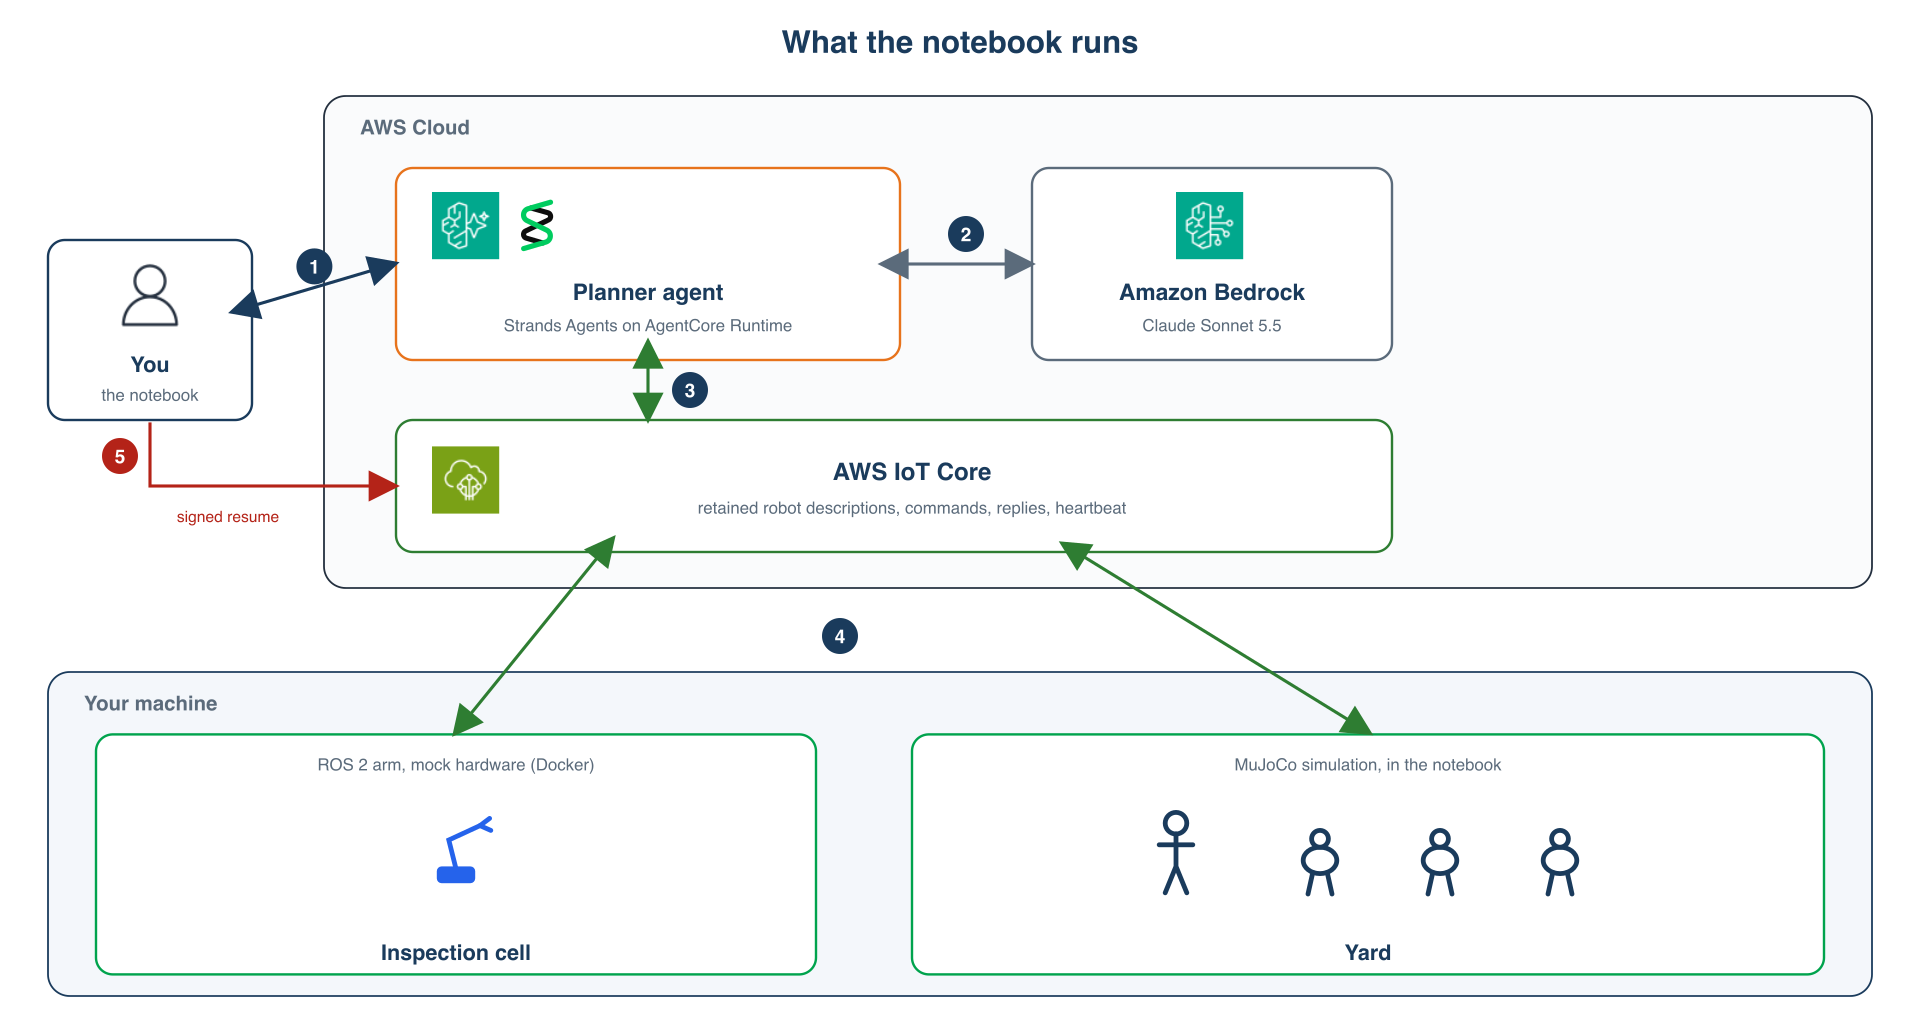

1. You send one goal to the planner agent on AgentCore Runtime.
2. The planner, built with Strands Agents, reasons over the goal with Claude Sonnet 5.5 on Amazon Bedrock.
3. The planner reaches the robots through AWS IoT Core: each robot describes itself once, as a retained message, and
   the planner sends commands by name. Its 0.5 s heartbeat is each robot's dead-man's switch.
4. Each robot runs a robot host that enforces the safety rules, runs its skills locally and reports what happened.
5. Only you, the operator, can resume a stopped robot, with a signed command the planner can't send.

## Step 1: Set up

This cell loads what the set-up created: the operator's key (the planner never gets it), the planner's runtime, and
a client that sends a goal once and never retries it, because a goal sent twice would make every robot do its work
twice.

In [1]:
import json, os, sys, time, uuid
sys.path[:0] = [os.path.abspath("fleet"), os.path.abspath("yard")]
os.environ.setdefault("MUJOCO_GL", "cgl" if sys.platform == "darwin" else "egl")

import boto3
from botocore.config import Config
from cryptography.hazmat.primitives import serialization
from IPython.display import Video, display
from PIL import Image

import robot_host
from iotlink import Link
from planner import Fleet
from sim_yard import SimYard, run_goal

robot_host.print = lambda *a, **k: None  # keep each robot host's request log out of the notebook
REGION, TENANT = os.environ.get("AWS_REGION", "us-west-2"), "site"
PLANNER_ARN = open("runtime_arn.txt").read().strip()
KEY = serialization.load_pem_private_key(open("fleet/operator_key.pem", "rb").read(), None)
PUB = KEY.public_key().public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw).hex()
agentcore = boto3.client("bedrock-agentcore", region_name=REGION,
                         config=Config(read_timeout=900, retries={"total_max_attempts": 1}))
os.makedirs("media", exist_ok=True)
print("planner runtime:", PLANNER_ARN.split("/")[-1].rsplit("-", 1)[0], "| region:", REGION)

planner runtime: fleet_planner | region: us-west-2


In [2]:
# Two yards in one tenant would mix fleets: wait (up to 10 minutes) until no other yard is online.
watch, t0 = Fleet(TENANT), time.time()
while (others := [d["device"] for d in watch.devices(timeout=4.0) if d["device"].startswith(("duck-", "g1-"))]):
    if time.time() - t0 > 600:
        raise RuntimeError(f"another yard is online in this tenant: {others}")
    time.sleep(10)
print("robots online before the yard starts:", sorted(d["device"] for d in watch.devices(timeout=1.0)))
watch.close()

robots online before the yard starts: ['ros-arm']


## Step 2: Robots describe themselves

Each robot is a `Device` with its own IoT Core connection. When it connects, it publishes its zone and its skills,
with a one-line description of each, as a retained message. A skill is a trained policy that runs on the robot for a
bounded time and ends with a check the robot measures.

The yard has three zones: a dock (the yellow pad), a yard lane (the pale strip with a blue checkpoint post) and a yard
bin (the green walled area). The yard robots only know the skills trained for them, so the yard jobs are those skills
given site names: guarding the dock is the G1 walking onto the pad, patrolling the lane is a walker walking along it,
and delivering the yard part is a walker kicking the red ball into the bin.

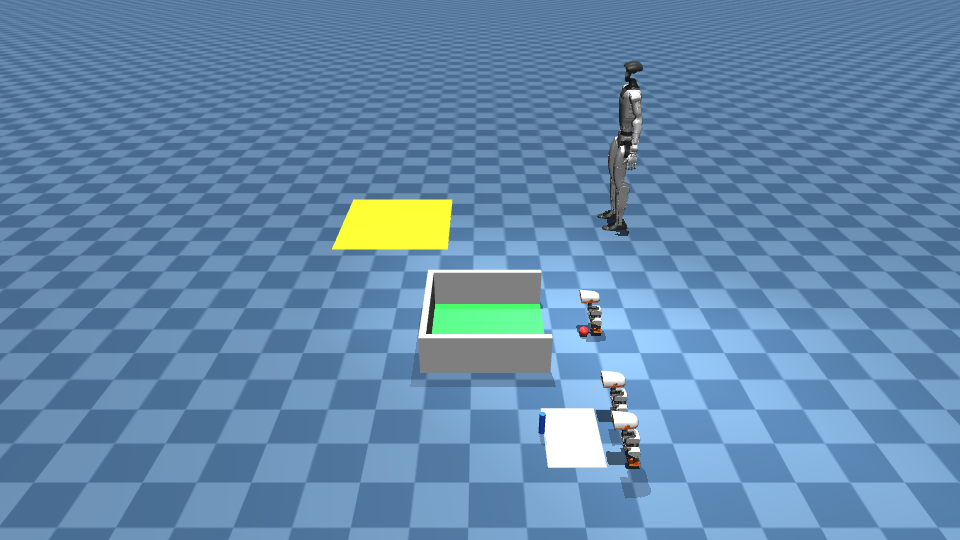

duck-1   zone yard-bin         skills ['kick', 'turn', 'walk']
duck-2   zone yard-lane        skills ['kick', 'turn', 'walk']
duck-3   zone yard-lane        skills ['kick', 'turn', 'walk']
g1-1     zone dock             skills ['walk']
ros-arm  zone inspection-cell  skills ['inspect', 'present']



g1-1 describes its skill: {'walk': {'seconds': 4.0, 'does': 'walk about 1.7 m onto the dock pad and stand guard there'}}


In [3]:
yard = SimYard(PUB, TENANT)
display(Image.fromarray(yard.world.render("overview")))

fleet = Fleet(TENANT)  # reads every robot's retained description as it connects
online = {d["device"]: d for d in fleet.devices(min_count=5, timeout=30)}
for name, d in sorted(online.items()):
    print(f"{name:8s} zone {d['zone']:16s} skills {d['skills']}")
call = fleet.link.call
print("\ng1-1 describes its skill:", call("g1-1", "describe")["skills"])

## Step 3: The five rules, live

Every command passes the same five rules on the robot, written as code rather than left to the model. Each check
below goes over IoT Core to a robot and back.

In [4]:
def refused(fn, *args, **kwargs):
    try:
        fn(*args, **kwargs)
        return "NOT refused"
    except (RuntimeError, ConnectionError) as e:
        return str(e)[:150]

# Rule 1: a target outside a joint's limits is refused, never clamped, and nothing moves.
joint, (lo, hi) = next(iter(call("duck-3", "describe")["joints"].items()))
print("rule 1:", refused(call, "duck-3", "act", targets={joint: hi + 1.0}, seconds=1.0))
# Rule 5: skills are named and bounded; a robot runs only the skills it offers.
print("rule 5:", refused(call, "duck-3", "skill", name="fly"))

rule 1: duck-3 refused act: ValueError: left_hip_yaw=1.5236 is outside its range [-0.4363, 0.5236]; refused, nothing moved


rule 5: duck-3 refused skill: LookupError: no skill 'fly'; this robot offers ['kick', 'turn', 'walk']


### Stop a robot, and resume it

Rules 2 and 3. A stop latches, and every motion is refused until a person resumes the robot. The planner can stop a
robot but can't resume one: it has no resume tool, and its IAM role is denied the resume and approval topics. The
operator resumes it with a signature over this robot and this stop, which is what `fleet/resume.py` sends. This is a
software stop, so keep each robot's hardware emergency stop as well.

In [5]:
t = time.perf_counter()
call("duck-3", "estop")
print(f"rule 2: stop acknowledged in {time.perf_counter() - t:.2f} s; a skill now:",
      refused(call, "duck-3", "skill", name="turn"))
print("rule 3: an unsigned resume:", refused(call, "duck-3", "resume", operator="planner"))
print("        the planner's tools:", [t.tool_name for t in fleet.tools()])

iam, account = boto3.client("iam"), boto3.client("sts").get_caller_identity()["Account"]
role = f"arn:aws:iam::{account}:role/fleet-planner-runtime"
for topic in (f"{TENANT}/duck-3/rpc/resume", f"{TENANT}/arm-1/approval", f"{TENANT}/duck-3/rpc/skill"):
    arn = f"arn:aws:iot:{REGION}:{account}:topic/{topic}"
    verdict = iam.simulate_principal_policy(PolicySourceArn=role, ActionNames=["iot:Publish"],
                                            ResourceArns=[arn])["EvaluationResults"][0]["EvalDecision"]
    print(f"        may the planner's role publish {topic}? {verdict}")

epoch = call("duck-3", "epoch")["epoch"]  # what fleet/resume.py signs
print("        the operator's signed resume:",
      call("duck-3", "resume", operator="operator", signature=KEY.sign(f"duck-3:{epoch}".encode()).hex()))

rule 2: stop acknowledged in 0.23 s; a skill now: duck-3 refused skill: PermissionError: e-stop is latched; an operator must resume this robot
rule 3: an unsigned resume: duck-3 refused resume: PermissionError: resume needs the operator's signature for this stop; refused
        the planner's tools: ['list_devices', 'describe', 'run_skill', 'run_sequence', 'act', 'skill_status', 'wait_for_skill', 'emergency_stop']


        may the planner's role publish site/duck-3/rpc/resume? explicitDeny
        may the planner's role publish site/arm-1/approval? explicitDeny


        may the planner's role publish site/duck-3/rpc/skill? allowed


        the operator's signed resume: {'estopped': False, 'resumed_by': 'operator'}


### The watchdog

Rule 4. A commander starts a 4-second walk and then goes quiet. The robot stops hearing its heartbeat and holds
instead of walking on.

In [6]:
x0 = float(yard.pos("duck-3")[0])
quiet = Link(f"planner-quiet-{uuid.uuid4().hex[:6]}", TENANT)
quiet.publish(f"{TENANT}/heartbeat/{quiet.client_id}", {"ts": time.time()})
quiet.call("duck-3", "skill", name="walk")
time.sleep(0.8)
quiet.close()  # the commander goes quiet mid-walk
while call("duck-3", "status")["running"]:
    time.sleep(0.2)
walked = float(yard.pos("duck-3")[0]) - x0
print("rule 4:", call("duck-3", "status")["stopped_by"], f"| walked {walked:.2f} m of a 4 s walk (about 0.4 m in full)")
yard.lane0["duck-3"] = float(yard.pos("duck-3")[0])  # the lane check measures from where duck-3 stands now

rule 4: watchdog: commander went quiet, holding | walked 0.15 m of a 4 s walk (about 0.4 m in full)


## Step 4: Run the morning shift

One goal in plain language, through the planner on AgentCore Runtime. It names no robot and no skill. The planner
reads zones and skill descriptions, assigns the work, runs it in parallel, waits, and reports what each robot's check
measured. "Unload the truck" is a task no robot can do: watch what the planner does with it.

In [7]:
GOAL = ("Start the morning shift. In the inspection cell, show the part to the camera. In the yard, guard the dock, "
        "patrol the yard lane, and kick the yard part into the yard bin. Unload the truck. Robots may work at the same time.")
out, outcome, clip = run_goal(yard, agentcore, PLANNER_ARN, GOAL, "media/shift.mp4")

print(f"planner time {out['total_s']} s | skills each robot was sent (from the ledger): {out['ledger_skills_sent']}")
print("measured:", json.dumps(outcome, indent=1))
print("\nthe planner's report:\n" + out["reply"])
display(Video(clip, width=960))  # saved as media/shift.mp4; GitHub's notebook view doesn't play video

planner time 18.57 s | skills each robot was sent (from the ledger): {'ros-arm': ['present'], 'g1-1': ['walk'], 'duck-2': ['walk'], 'duck-1': ['kick']}
measured: {
 "part_in_bin": [
  0.96,
  [
   0.3,
   0.16
  ]
 ],
 "g1_on_dock": {
  "at": [
   1.21,
   -1.51
  ],
  "z": 0.77,
  "ok": true
 },
 "lane_advanced_m": {
  "duck-2": 0.39,
  "duck-3": -0.0
 },
 "stopped_by": {
  "duck-1": "done",
  "duck-2": "done",
  "duck-3": "watchdog: commander went quiet, holding",
  "g1-1": "done"
 },
 "ros_arm_joints": "{\"j1\": 0.0, \"j2\": 0.6, \"j3\": -0.6, \"j4\": 0.0}"
}

the planner's report:
Three of the four tasks are done. Nothing can unload the truck.

- **Inspection cell:** `ros-arm` ran `present` and held the part up to the camera. Its check passed.
- **Dock:** `g1-1` walked onto the dock pad to guard it. Its check passed.
- **Yard lane:** `duck-2` walked about 0.39 m along the lane. Its check passed.
- **Yard bin:** `duck-1` kicked the part and it landed in the bin. Its check passed.
- 

## Step 5: Finished is not completed

A skill can run to its end without achieving its purpose. Here the part is moved off its spot before the kick. The
kick finishes, and the robot's check says the part didn't reach the bin. The planner reads the check, not the fact
that the skill finished.

In [8]:
yard.world.set_pose("part", position=(0.06, -0.25, 0.03))  # off the kicking foot
call("duck-1", "skill", name="kick")
while call("duck-1", "status")["running"]:
    time.sleep(0.2)
status = call("duck-1", "status")
print("kick stopped_by:", status["stopped_by"], "| check:", status.get("check"))

kick stopped_by: done | check: {'ok': False, 'in_bin_after_s': None, 'entered_at': None}


## Step 6: A robot drops off the network

The same goal, in a fresh yard. One second into the lane patrol, that walker's robot host loses its network. On the
robot, the watchdog stops hearing the planner's heartbeat and holds it. The planner gets no answer, so the outcome is
unknown and it says so. Only a robot in the same zone can take the task over, so it gives the patrol to the other
walker in the yard lane.

In [9]:
yard.close()
yard = SimYard(PUB, TENANT)
fleet.devices(min_count=5, timeout=30)
out, outcome, clip = run_goal(yard, agentcore, PLANNER_ARN, GOAL, "media/dropout.mp4", cut=True)

print("what happened:", yard.log)
print("measured:", json.dumps(outcome, indent=1))
print("\nthe planner's report:\n" + out["reply"])
display(Video(clip, width=960))

what happened: [{'t': 10.04, 'dispatched': 'walk', 'to': 'duck-2'}, {'t': 10.04, 'dispatched': 'kick', 'to': 'duck-1'}, {'t': 10.06, 'dispatched': 'walk', 'to': 'g1-1'}, {'t': 11.04, 'offline': 'duck-2'}, {'t': 25.39, 'dispatched': 'walk', 'to': 'duck-3'}]
measured: {
 "part_in_bin": [
  1.45,
  [
   0.3,
   0.16
  ]
 ],
 "g1_on_dock": {
  "at": [
   1.22,
   -1.58
  ],
  "z": 0.76,
  "ok": true
 },
 "lane_advanced_m": {
  "duck-2": 0.07,
  "duck-3": 0.41
 },
 "stopped_by": {
  "duck-1": "done",
  "duck-2": "watchdog: commander went quiet, holding",
  "duck-3": "done",
  "g1-1": "done"
 },
 "ros_arm_joints": "{\"j1\": 0.0, \"j2\": 0.6, \"j3\": -0.6, \"j4\": 0.0}"
}

the planner's report:
Three of the four tasks are done. The yard patrol finished on a different robot than planned, and nobody can unload the truck.

- **Inspection cell:** Done. ros-arm held the part up to the camera, and the check passed.
- **Dock guard:** Done. g1-1 walked onto the dock pad, and the check passed.
- **Yar

## Step 7: The same pattern on real arms

The packing cell is the same robot host with a LeRobot SO-101 body and one skill, `pick`: an Action Chunking with
Transformers (ACT) policy that runs on the robot host at 30 Hz. Each arm stands in its own zone (`black-parts`,
`blue-parts`), because each policy picks from one fixed spot. A pick waits for the operator's signed approval before
the arm moves, and the arm host refuses raw joint moves from the planner. This part needs the arms, so it isn't run
here. See `so101/README.md`.

## Clean up

In [10]:
yard.close()
fleet.close()
print("the yard robots left the fleet; next: python planner_runtime/teardown.py, then docker rm -f ros-arm")

the yard robots left the fleet; next: python planner_runtime/teardown.py, then docker rm -f ros-arm
